# Stage 3 — Splits, metrics and baselines

| Part | Prompt | Code |
|---|---|---|
| 1 | 3.1 split design | `src/splits.py`, `tests/test_splits.py` |
| 2 | 3.2 metrics | `src/metrics.py`, `tests/test_metrics.py` |
| 3 | 3.3 baselines | `src/baselines.py` |
| 4 | skeptical review | — |

**The test set (targets 2020–2025) is not loaded or scored anywhere in this notebook.** `splits.test_index` refuses to
return it unless `confirm_final=True` is passed, which we will only do when you say "final evaluation".

### Step 1 — Setup

**WHAT:** load `features_A.parquet` (targets are identical in A and B; the baselines only use the season columns that
both sets share) and today's rainfall in mm from `clean_daily.parquet` (needed for exact threshold comparisons in the
persistence baseline: `expm1(log1p(x))` can differ from x in the last decimal and flip a value sitting exactly at 1.0 mm).

**WHY:** rule 15 — inputs come from `data/processed` only.

**Alternatives considered:** recovering rain from `rain_log1p` — risky at threshold boundaries, as explained.

**Look for:** 16,406 rows; the development index ends with target date 2019-12-31.

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

SEED = 42; np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import splits as S, metrics as M, baselines as B

PROC, FIG, TAB = ROOT / "data/processed", ROOT / "reports/figures", ROOT / "reports/tables"
pd.set_option("display.width", 170, "display.max_columns", 40, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
def pytest(path):
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", str(ROOT / path)],
                       capture_output=True, text=True, cwd=ROOT)
    print(r.stdout[-800:], r.stderr[-300:])

df = pd.read_parquet(PROC / "features_A.parquet")
rain_today = pd.read_parquet(PROC / "clean_daily.parquet")["PRECTOTCORR"].reindex(df.index)
dev = S.dev_index(df.index)
print("rows:", len(df), "| development rows:", len(dev), "| last dev target:", S.target_dates(dev).max().date())

rows: 16406 | development rows: 14214 | last dev target: 2019-12-31


**Interpretation:** 16,406 rows, of which 14,214 are development rows; the last development target is 2019-12-31 (the
row dated 2019-12-31 is excluded, Decision 2.6).

**Decision:** all work below uses development rows only.

**Paper note:** *Model development used the 14,214 daily samples whose target dates fell between 1981 and 2019.*

# Part 1 — Prompt 3.1: split design

### Step 2 — Build the 5 expanding-window folds and the deep-learning split

**WHAT:** every split is defined by the **target date** (t+1). Training uses all target years from 1981 up to the fold's
end year, minus a **1-day purge**: the last training row is removed, so one calendar day lies between the last training
target and the first validation target. Validation covers 3 target years.

| split | train (target years) | validate |
|---|---|---|
| fold 1 | 1981–2004 | 2005–2007 |
| fold 2 | 1981–2007 | 2008–2010 |
| fold 3 | 1981–2010 | 2011–2013 |
| fold 4 | 1981–2013 | 2014–2016 |
| fold 5 | 1981–2016 | 2017–2019 |
| DL | 1981–2014 | 2015–2019 |

**WHY expanding windows?** They imitate real use: a forecaster trains on all past data and predicts the next years.
Each validation block is *after* its training data. The purge is a safety margin: with t+1 targets, the last training
target (day T) is also "today's rain" in the first validation row's features; removing it ensures no day serves both as a
training target and as the reference day of a validation forecast.

**Alternatives considered:** sliding (fixed-length) windows — would discard old data and reduce sample size, though they
could adapt better to the 2016 regime (a Stage-6 ablation); more folds with 1-year validation — noisier per fold.

**Look for:** sizes, and how the rain-day base rate and mean rain differ between each fold's training and validation data.

In [2]:
SPLITS = {f"fold{k}": s for k, s in enumerate(S.cv_folds(df.index), 1)}
SPLITS["dl"] = S.dl_split(df.index)
FOLDS = [k for k in SPLITS if k.startswith("fold")]
td = lambda i: S.target_dates(i)
split_tab = pd.DataFrame({k: {
    "train_targets": f"{td(tr).min().date()} .. {td(tr).max().date()}", "n_train": len(tr),
    "val_targets": f"{td(va).min().date()} .. {td(va).max().date()}", "n_val": len(va),
    "gap_days": (td(va).min() - td(tr).max()).days - 1,
    "rain_day_rate_train": df.loc[tr, "y_cls"].mean(), "rain_day_rate_val": df.loc[va, "y_cls"].mean(),
    "mean_mm_train": df.loc[tr, "y_reg"].mean(), "mean_mm_val": df.loc[va, "y_reg"].mean()} for k, (tr, va) in SPLITS.items()}).T
split_tab.to_csv(TAB / "03_split_design.csv")
split_tab

,train_targets,n_train,val_targets,n_val,gap_days,rain_day_rate_train,rain_day_rate_val,mean_mm_train,mean_mm_val
fold1,1981-01-31 .. 2004-12-30,8735,2005-01-01 .. 2007-12-31,1095,1,0.476,0.5,6.087,8.419
fold2,1981-01-31 .. 2007-12-30,9830,2008-01-01 .. 2010-12-31,1096,1,0.479,0.514,6.347,7.988
fold3,1981-01-31 .. 2010-12-30,10926,2011-01-01 .. 2013-12-31,1096,1,0.483,0.488,6.511,7.896
fold4,1981-01-31 .. 2013-12-30,12022,2014-01-01 .. 2016-12-31,1096,1,0.483,0.526,6.638,10.518
fold5,1981-01-31 .. 2016-12-30,13118,2017-01-01 .. 2019-12-31,1095,1,0.487,0.589,6.962,16.103
dl,1981-01-31 .. 2014-12-30,12387,2015-01-01 .. 2019-12-31,1826,1,0.483,0.575,6.67,14.421


**Interpretation:**
- Each fold has ~1,095 validation days (3 years); training grows from 8,735 to 13,118 rows; the gap is exactly 1 day.
- **Every validation block is wetter than its training data**, not only after 2016: mean target rain is 6.1–7.0 mm/day in
  training vs 7.9–8.4 mm/day in folds 1–3, 10.5 in fold 4 and **16.1 in fold 5** (2.3× the training mean). This reflects both
  PRECTOTCORR breaks (~2000 and 2016): the 1981–1997 low-rain years sit in every training set.
- The rain-day base rate rises from ~0.48 (train) to 0.50–0.53 (folds 1–4) and **0.59 in fold 5**.

**Decision:** every model trained on all years will be pushed towards too-low rainfall; the bias is largest in fold 5 and the
DL split. We report folds individually, not only their mean.

**Paper note:** *Five expanding-window folds with three-year validation blocks (2005–2019) and a one-day purge gap were used
for model selection; owing to the inhomogeneity of PRECTOTCORR, validation periods were systematically wetter than the
corresponding training periods (up to 2.3-fold in mean rainfall for 2017–2019).*

### Step 3 — Timeline figure

**WHAT:** the 90-day running mean of the target rainfall (top) and the train / validation / locked-test periods of each
split (bottom).

**WHY:** one picture that a reviewer can check the protocol against, and it shows where the 2016 regime jump sits
relative to each validation block.

**Alternatives considered:** plotting daily rainfall — too noisy at 45 years; the 90-day mean shows the seasonal cycle
and the level shift.

**Look for:** fold 4's validation block straddles 2016; fold 5 and the DL validation lie inside the new regime, while
most of their training data do not.

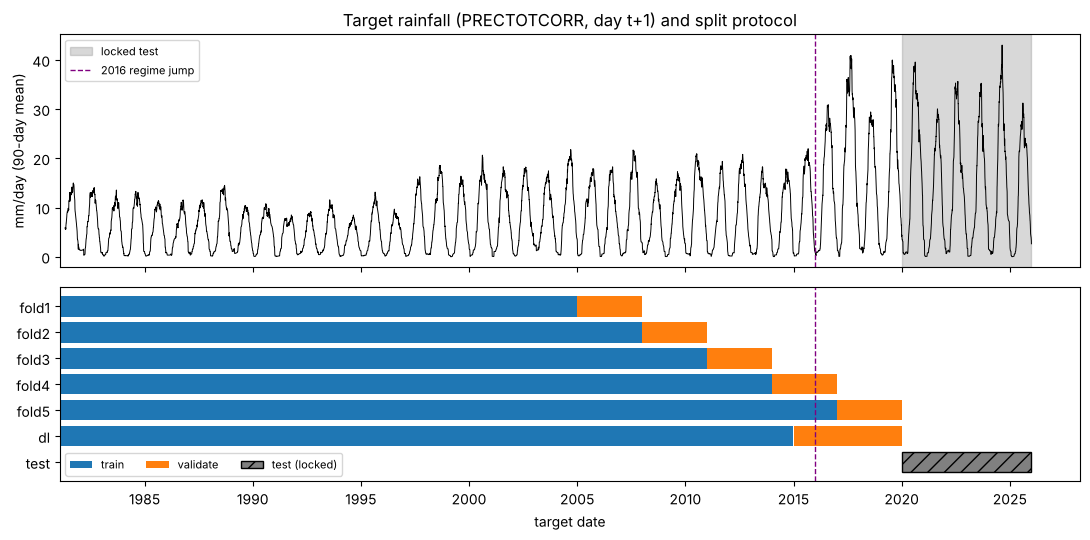

In [3]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
y_by_target = pd.Series(df["y_reg"].to_numpy(), index=td(df.index))
ax0.plot(y_by_target.rolling(90).mean(), lw=0.7, color="k")
ax0.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"), color="grey", alpha=0.3, label="locked test")
ax0.axvline(pd.Timestamp("2016-01-01"), color="purple", ls="--", lw=1, label="2016 regime jump")
ax0.set(ylabel="mm/day (90-day mean)", title="Target rainfall (PRECTOTCORR, day t+1) and split protocol"); ax0.legend(fontsize=8)
names = list(SPLITS) + ["test"]
for i, name in enumerate(names):
    if name == "test":
        ax1.barh(i, pd.Timestamp("2025-12-31") - pd.Timestamp("2020-01-01"), left=pd.Timestamp("2020-01-01"),
                 color="grey", hatch="//", edgecolor="k", label="test (locked)")
        continue
    tr, va = SPLITS[name]
    ax1.barh(i, td(tr).max() - td(tr).min(), left=td(tr).min(), color="tab:blue", label="train" if i == 0 else None)
    ax1.barh(i, td(va).max() - td(va).min(), left=td(va).min(), color="tab:orange", label="validate" if i == 0 else None)
ax1.set_yticks(range(len(names)), names); ax1.invert_yaxis(); ax1.axvline(pd.Timestamp("2016-01-01"), color="purple", ls="--", lw=1)
ax1.legend(fontsize=8, loc="lower left", ncol=3); ax1.set_xlabel("target date")
fig.tight_layout(); save(fig, "03_split_timeline.png"); plt.show()

**Interpretation:** the timeline shows the protocol: training (blue) always precedes validation (orange), and the test block
(hatched) is untouched. The top panel makes the data problem visible at a glance: seasonal peaks of ~10–14 mm/day before
~1997, ~15–20 mm/day in 1998–2015, and 30–40 mm/day from 2016 — including the locked test period. Fold 4's validation
straddles the jump; fold 5 and the DL validation are entirely in the new regime.

**Decision:** this figure goes into the paper's Methods (Figure: evaluation design).

**Paper note:** *Figure X illustrates the chronological evaluation design together with the 90-day running mean of the
target series, highlighting the discontinuity in 2016 relative to the validation and test periods.*

### Step 4 — Why random k-fold would be misleading here (a direct demonstration)

**WHAT:** under random 5-fold CV on the development rows, count how often a validation row's **target** is visible to
the model during training. Row t's target is rain on day t+1; but row t+1's feature `rain_log1p` *is* log(1 + rain on day
t+1). So if row t+1 is in the training set, the model has been shown the validation answer as an input.
We first verify that identity, then count.

**WHY this matters:**
1. **Direct target leakage through neighbouring rows** (measured below).
2. **Autocorrelation:** even without exact copies, neighbouring days are nearly identical (RH2M lag-1 ACF = 0.94), so a
   random split tests "interpolation between known days", not forecasting the future.
3. **Non-stationarity:** random folds mix post-2016 days into training, so the regime shift would be invisible and
   scores would be optimistic for the real task (forecasting a future that may differ from the past).

**Alternatives considered:** `TimeSeriesSplit` from scikit-learn — chronological but splits by row count, not by calendar
year, and has no notion of target date; our year-based folds are easier to report.

**Look for:** the share of validation targets seen in training: ~80 % for random k-fold vs 0 % for our folds.

In [4]:
nxt = df.index + pd.Timedelta(days=1)
ok = nxt.isin(df.index)
assert np.allclose(df.loc[nxt[ok], "rain_log1p"].to_numpy(), df.loc[df.index[ok], "y_reg_log"].to_numpy())
print("verified: rain_log1p(row t+1) == y_reg_log(row t) for all", ok.sum(), "rows")

def share_target_seen(train, val):
    return np.isin(val + pd.Timedelta(days=1), train).mean()

rand = [share_target_seen(dev[a], dev[b]) for a, b in KFold(5, shuffle=True, random_state=SEED).split(dev)]
ours = [share_target_seen(tr, va) for tr, va in (SPLITS[k] for k in FOLDS)]
pd.DataFrame({"random 5-fold": rand, "expanding folds (ours)": ours}, index=[f"fold {i}" for i in range(1, 6)]).round(3)

verified: rain_log1p(row t+1) == y_reg_log(row t) for all 16405 rows


,random 5-fold,expanding folds (ours)
fold 1,0.805,0.0
fold 2,0.802,0.0
fold 3,0.803,0.0
fold 4,0.789,0.0
fold 5,0.803,0.0


**Interpretation:** the identity holds for all 16,405 consecutive pairs, so this is not a hypothetical risk. With random
5-fold CV, **~80 % of validation targets appear as an input feature of a training row** (row t+1 is in training with
probability 4/5). A flexible model could partly "look up" the answer. With our expanding folds the share is **0 %**.

**Decision:** random k-fold is excluded for every model, including hyper-parameter tuning inside Stage 4 (inner splits must
also be chronological).

**Paper note:** *Random k-fold cross-validation was avoided because, with lagged predictors, the target of a validation
sample appears as a predictor of the adjacent training sample in about 80 % of cases, which would inflate skill estimates.*

### Step 5 — Unit tests for the split protocol

**WHAT:** run `tests/test_splits.py`: no overlap, strict chronological order, purge gap ≥ 1 day, no split touches a
2020+ target, expanding windows, 5 folds with the right validation years, and the test getter raising `PermissionError`
unless `confirm_final=True` (also for "truthy" values like `1` or `"yes"`).

**WHY:** the protocol is the foundation of every number in the paper; tests make it impossible to break silently.

**Look for:** all tests pass.

In [5]:
pytest("tests/test_splits.py")

.......................                                                  [100%]
23 passed in 0.49s
 


**Interpretation:** all 23 split tests pass, including the locked test getter (it refuses `False`, `None`, `"yes"` and `1`;
only the literal `True` unlocks it).

**Decision:** `src/splits.py` is the only way later notebooks may create splits.

**Paper note:** *The split protocol was enforced programmatically and verified with automated tests.*

# Part 2 — Prompt 3.2: metrics

### Step 6 — What each metric measures

**Probabilistic classification** (forecast = probability p of rain ≥ threshold)

| metric | definition | range (best) | what it tells us |
|---|---|---|---|
| ROC-AUC | P(random rain day gets higher p than random dry day) | 0.5–1 (1) | **ranking/discrimination** only; ignores calibration and base rate |
| PR-AUC (average precision) | area under precision–recall curve | base rate–1 (1) | discrimination focused on the rain class; **its no-skill level = base rate**, so compare only at equal base rates |
| Brier score | mean (p − y)² | 0–1 (0) | accuracy of probabilities (calibration + sharpness) |
| **BSS** | 1 − Brier / Brier(climatology) | −∞–1 (1) | **skill relative to climatology**; 0 = no better than climatology. Our main probabilistic skill score |
| log loss | −mean[y log p + (1−y) log(1−p)] | 0–∞ (0) | punishes confident wrong forecasts strongly |
| ECE | Σ_bins (n_b/N)·\|observed freq − mean p\| | 0–1 (0) | calibration error: "when we say 70 %, does it rain 70 % of the time?" |
| calibration curve | observed frequency vs mean p per bin | — | the picture behind ECE (reliability diagram) |

**Yes/no forecasts** (p ≥ decision threshold); tp = hits, fp = false alarms, fn = misses, tn = correct negatives

| metric | formula | note |
|---|---|---|
| accuracy | (tp + tn)/N | misleading when one class dominates (winter) |
| balanced accuracy | (POD + tn/(tn+fp))/2 | average of the two class-wise hit rates |
| precision | tp/(tp + fp) | of forecast rain days, how many were wet |
| recall = POD | tp/(tp + fn) | probability of detection |
| F1 | 2tp/(2tp + fp + fn) | harmonic mean of precision and recall |
| FAR | fp/(tp + fp) | false alarm **ratio** (= 1 − precision), meteorological convention; not the false-alarm *rate* fp/(fp+tn) |
| CSI | tp/(tp + fp + fn) | threat score; ignores correct negatives (good for rare events) |
| HSS | 2(tp·tn − fp·fn) / [(tp+fn)(fn+tn) + (tp+fp)(fp+tn)] | accuracy relative to random chance; 0 = chance, 1 = perfect |

**Regression** (forecast = rain amount in mm)

| metric | note |
|---|---|
| MAE, RMSE | typical error; RMSE punishes large errors (heavy rain) more |
| bias | mean(forecast − observed); negative = underestimation |
| Pearson r / Spearman ρ | linear / rank association between forecast and observed |
| R² | 1 − MSE / var(observed): skill vs the *validation-period* mean (an unrealistic reference that uses future data) |
| **MSESS** | 1 − MSE / MSE(climatology): skill vs the training-period day-of-year climatology (a forecast that could actually be made) |
| MAE_wet, RMSE_wet | on days with observed rain ≥ 1 mm only (errors on dry days are easy) |
| recall/precision ≥ 20 and ≥ 50 mm | does the model forecast heavy-rain days when they occur, and are its heavy-rain forecasts right? |

**Decision threshold:** `choose_threshold` picks the probability cut-off that maximises CSI (or F1) on data the model was
**fitted** on; the value is then frozen and applied unchanged to later data. For the baselines we choose it on each
fold's **training** rows, so validation data never influence it.

**Block bootstrap:** resamples whole calendar months (year–month blocks) with replacement. Days within a month are
correlated; resampling single days would pretend we have more independent information than we do and give CIs that are
too narrow.

### Step 7 — Unit tests with hand-checked examples

**WHAT:** run `tests/test_metrics.py` and print the metrics for the 4-day example used in the tests, so you can verify
each number by hand: y = [1, 1, 0, 0], p = [0.9, 0.4, 0.6, 0.1], threshold 0.5 → 1 hit, 1 miss, 1 false alarm,
1 correct negative.

**WHY:** a metric bug would silently corrupt every comparison in the paper. Tiny examples with known answers are the
cheapest protection. (The test-writing itself caught one error — in my hand calculation of wet-day MAE, not in the code.)

**Look for:** all tests pass; CSI = 1/3, HSS = 0, ROC-AUC = 0.75, Brier = 0.185, BSS = 0.26.

In [6]:
pytest("tests/test_metrics.py")
demo = M.classification_metrics([1, 1, 0, 0], [0.9, 0.4, 0.6, 0.1], threshold=0.5, p_ref=[0.5] * 4)
pd.Series(demo).round(3).to_frame("value").T

.........                                                                [100%]
9 passed in 1.32s
 


,ROC_AUC,PR_AUC,Brier,BSS,log_loss,ECE,tp,fp,fn,tn,accuracy,balanced_accuracy,precision,recall_POD,F1,FAR,CSI,HSS,threshold
value,0.75,0.833,0.185,0.26,0.511,0.35,1.0,1.0,1.0,1.0,0.5,0.5,0.5,0.5,0.5,0.5,0.333,0.0,0.5


**Interpretation:** all 9 metric tests pass, and the demo matches the hand calculation: CSI = 1/3, HSS = 0 (no better than
chance), ROC-AUC = 0.75, Brier = 0.185, BSS = 0.26 vs a constant 0.5 forecast, ECE = 0.35. Writing the tests caught one
error in my *expected* value for wet-day MAE (0.5, not 1.0) — a reminder that the test expectation must also be checked.

**Decision:** `src/metrics.py` is the single implementation of every score in the paper.

**Paper note:** *All verification metrics were implemented in a shared module and validated against hand-calculated
examples.*

# Part 3 — Prompt 3.3: baselines

### Step 8 — Baseline definitions

All baselines are fitted on each split's **training rows only**:

| baseline | classification (probability of rain ≥ thr on day t+1) | regression (mm on day t+1) |
|---|---|---|
| 1. majority / mean | training base rate (constant); yes/no = majority training class | training mean |
| 2. persistence | P(rain tomorrow \| rain today) or P(rain tomorrow \| dry today), from training; yes/no = "rain today" | tomorrow = today |
| 3. climatology | rain frequency for the target day of year, circular ±7-day window, training years | same, mean mm |
| 4. seasonal | logistic regression on doy sin/cos (2 harmonics) | ridge on the same, clipped at 0 |
| extra: seasonal + persistence | logistic regression on sin/cos + rain-today flag | ridge on sin/cos + today's mm, clipped at 0 |

**Why the extra reference?** Stage 1 showed two independent sources of easy skill: season and persistence. Each of the
four requested baselines uses only one. A combined 5–6-parameter linear model is the simplest honest "season + persistence"
reference; an ML model that cannot beat it has learned nothing beyond these two facts.

**Reference forecasts for skill scores:** BSS and MSESS use the **climatology baseline of the same fold** (so climatology
scores exactly 0). Yes/no thresholds: chosen by CSI on the training rows (majority: fixed at 0.5 → majority class).

**Alternatives considered:** a 0.5 threshold for all models — arbitrary when base rates differ between thresholds and
regimes; CSI is the standard target for rain/no-rain verification. Deterministic models only → one run each (rule 8
does not apply).

**Look for:** — (definitions only)

### Step 9 — Evaluate all baselines on the 5 folds and the DL split

**WHAT:** for each split, each classification target (1.0 mm primary; 0.1 and 2.5 mm sensitivity) and the regression
target, fit the baselines on training rows, predict validation rows, and compute all metrics. Store every number in a
long table.

**WHY:** one long table (split × target × model × metric) is the raw material for every summary and figure; nothing
is computed twice in different ways.

**Alternatives considered:** fold-by-fold printouts — impossible to compare systematically.

**Look for:** the number of rows in the score table and no errors.

In [7]:
CLS = {"y_cls": 1.0, "y_cls_01": 0.1, "y_cls_25": 2.5}
rows, PRED = [], {}
for split, (tr, va) in SPLITS.items():
    for tgt, thr in CLS.items():
        p_tr = B.classification_baselines(df, rain_today, tr, tr, tgt, thr)
        p_va = B.classification_baselines(df, rain_today, tr, va, tgt, thr)
        for name, p in p_va.items():
            t = 0.5 if name == "majority" else M.choose_threshold(df.loc[tr, tgt], p_tr[name], "CSI")
            rows.append({"split": split, "target": tgt, "model": name,
                         **M.classification_metrics(df.loc[va, tgt], p, threshold=t, p_ref=p_va["climatology"])})
        PRED[split, tgt] = p_va
    r_va = B.regression_baselines(df, rain_today, tr, va)
    for name, yhat in r_va.items():
        rows.append({"split": split, "target": "y_reg", "model": name,
                     **M.regression_metrics(df.loc[va, "y_reg"], yhat, y_ref=r_va["climatology"])})
    PRED[split, "y_reg"] = r_va
scores = pd.DataFrame(rows)
scores.to_csv(TAB / "03_baseline_scores_long.csv", index=False)
scores[scores.split == "dl"].to_csv(TAB / "03_baseline_scores_dl_split.csv", index=False)
print("score table:", scores.shape, "| splits:", list(SPLITS), "| models:", scores.model.unique().tolist())

score table: (120, 35) | splits: ['fold1', 'fold2', 'fold3', 'fold4', 'fold5', 'dl'] | models: ['majority', 'persistence', 'climatology', 'seasonal', 'seasonal+persistence']


**Interpretation:** 120 rows = 6 splits × (3 classification targets + 1 regression target) × 5 baselines; all metrics in
one table (`03_baseline_scores_long.csv`; DL split separately in `03_baseline_scores_dl_split.csv`).

**Decision:** Stage 4 appends its models to the same long format so baselines and models are directly comparable.

**Paper note:** *All reference forecasts were evaluated with identical splits and metrics.*

### Step 10 — Mean ± std over the 5 folds: primary classification (≥ 1 mm) and regression

**WHAT:** average each metric over the 5 CV folds (std = fold-to-fold variation). The DL split is reported separately
(Step 15) because it is not one of the CV folds.

**WHY:** mean ± std over folds is the number that goes into the paper; the std shows how stable a result is across
periods — here also across regimes.

**Look for:** which baseline is best on each metric, and how large the stds are compared with the differences between
baselines.

In [8]:
CLS_COLS = ["ROC_AUC", "PR_AUC", "Brier", "BSS", "log_loss", "ECE", "accuracy", "balanced_accuracy",
            "precision", "recall_POD", "F1", "FAR", "CSI", "HSS", "threshold"]
REG_COLS = ["MAE", "RMSE", "bias", "pearson_r", "spearman_rho", "R2", "MSESS", "MAE_wet", "RMSE_wet",
            "recall_ge20", "precision_ge20", "recall_ge50", "precision_ge50"]
ORDER = ["majority", "persistence", "climatology", "seasonal", "seasonal+persistence"]

def summary(target, cols):
    s = scores[(scores.target == target) & scores.split.isin(FOLDS)]
    g = s.groupby("model")[cols].agg(["mean", "std"]).reindex(ORDER)
    g.round(4).to_csv(TAB / f"03_baseline_cv_summary_{target}.csv")
    return pd.DataFrame({c: g[(c, "mean")].map("{:.3f}".format) + " ± " + g[(c, "std")].map("{:.3f}".format) for c in cols})

cls_summary = summary("y_cls", CLS_COLS)
display(cls_summary.T)
reg_summary = summary("y_reg", REG_COLS).rename(index={"majority": "mean"})
reg_summary.T

model,majority,persistence,climatology,seasonal,seasonal+persistence
ROC_AUC,0.500 ± 0.000,0.878 ± 0.020,0.928 ± 0.017,0.928 ± 0.017,0.945 ± 0.014
PR_AUC,0.523 ± 0.039,0.841 ± 0.037,0.920 ± 0.034,0.917 ± 0.033,0.932 ± 0.028
Brier,0.251 ± 0.001,0.108 ± 0.014,0.106 ± 0.010,0.106 ± 0.009,0.086 ± 0.010
BSS,-1.394 ± 0.213,-0.020 ± 0.104,0.000 ± 0.000,-0.007 ± 0.011,0.184 ± 0.058
log_loss,0.695 ± 0.002,0.374 ± 0.035,0.353 ± 0.023,0.354 ± 0.022,0.298 ± 0.027
ECE,0.042 ± 0.037,0.039 ± 0.018,0.065 ± 0.025,0.067 ± 0.023,0.043 ± 0.017
accuracy,0.477 ± 0.039,0.879 ± 0.021,0.865 ± 0.019,0.867 ± 0.018,0.890 ± 0.017
balanced_accuracy,0.500 ± 0.000,0.878 ± 0.020,0.866 ± 0.021,0.869 ± 0.019,0.890 ± 0.016
precision,nan ± nan,0.883 ± 0.027,0.868 ± 0.048,0.868 ± 0.049,0.879 ± 0.037
recall_POD,0.000 ± 0.000,0.883 ± 0.027,0.875 ± 0.020,0.882 ± 0.020,0.916 ± 0.005


model,mean,persistence,climatology,seasonal,seasonal+persistence
MAE,10.724 ± 2.941,7.904 ± 1.618,8.100 ± 2.464,8.157 ± 2.494,7.079 ± 1.676
RMSE,18.047 ± 5.931,15.959 ± 3.763,16.233 ± 5.654,16.242 ± 5.674,14.008 ± 3.956
bias,-3.676 ± 3.206,-0.000 ± 0.000,-3.693 ± 3.202,-3.666 ± 3.196,-2.124 ± 1.789
pearson_r,nan ± nan,0.572 ± 0.080,0.486 ± 0.034,0.486 ± 0.033,0.618 ± 0.061
spearman_rho,nan ± nan,0.824 ± 0.022,0.747 ± 0.026,0.751 ± 0.023,0.821 ± 0.022
R2,-0.042 ± 0.045,0.143 ± 0.161,0.163 ± 0.068,0.162 ± 0.070,0.358 ± 0.053
MSESS,-0.248 ± 0.056,-0.037 ± 0.254,0.000 ± 0.000,-0.001 ± 0.004,0.228 ± 0.106
MAE_wet,14.393 ± 4.472,14.134 ± 1.821,13.311 ± 3.935,13.285 ± 3.965,11.827 ± 2.389
RMSE_wet,23.932 ± 7.301,21.681 ± 4.199,21.924 ± 6.945,21.939 ± 6.967,18.989 ± 4.672
recall_ge20,0.000 ± 0.000,0.509 ± 0.148,0.000 ± 0.000,0.000 ± 0.000,0.321 ± 0.132


**Interpretation — classification (≥ 1 mm):**
- **Season alone gives very high discrimination:** climatology ROC-AUC **0.928 ± 0.017**, PR-AUC 0.920. This is not a bug —
  it is the monsoon cycle (rain in July ≈ 93 %, in January ≈ 5 %).
- **Persistence** has lower ROC-AUC (0.878; it issues only two probability values, so its ranking is coarse) but better
  yes/no scores than climatology (CSI 0.791 vs 0.771) and BSS ≈ 0 (−0.020 ± 0.104).
- **Seasonal + persistence is clearly best on every metric:** ROC-AUC 0.945, BSS **0.184 ± 0.058**, CSI 0.813, HSS 0.780,
  log loss 0.298. The two sources of skill are complementary.
- The seasonal logistic model reproduces climatology (BSS −0.007) — a smooth 2-harmonic curve is as good as the empirical
  day-of-year frequency.
- Majority: BSS −1.39, CSI 0 — useless, as expected; it only anchors the scale.

**Interpretation — regression (mm):**
- Seasonal + persistence: MAE **7.08 ± 1.68**, RMSE 14.0, MSESS **0.228 ± 0.106**, R² 0.36. Persistence: MAE 7.90 but MSESS
  −0.04 ± 0.25 (strongly fold-dependent, Step 13). Climatology: MAE 8.10.
- All baselines that learn a *level* from training data are biased by **−3.7 mm/day** on average (the regime problem);
  persistence is unbiased by construction.
- Heavy rain: only persistence forecasts ≥ 50 mm at all (recall 0.30) because it copies yesterday's extremes; smooth
  baselines never reach 20 mm. Detecting heavy rain will be the hardest part of the regression task.

**Decision:** the **seasonal + persistence** model is the reference that Stage-4 models must beat (see "Implications").

**Paper note:** *Climatology alone achieved a ROC-AUC of 0.93 for next-day rain occurrence, and a logistic model combining
seasonal harmonics with same-day rain occurrence reached a Brier skill score of 0.18 ± 0.06 relative to climatology,
establishing a demanding reference for the machine-learning models.*

### Step 11 — Sensitivity thresholds (0.1 mm and 2.5 mm)

**WHAT:** the same summary for the two sensitivity targets (key metrics only; full tables saved).

**WHY:** we promised to check whether conclusions depend on the threshold.

**Look for:** whether the ranking of baselines is the same as at 1.0 mm.

In [9]:
KEY = ["ROC_AUC", "PR_AUC", "BSS", "CSI", "HSS"]
sens = pd.concat({t: summary(t, CLS_COLS)[KEY] for t in ("y_cls_01", "y_cls", "y_cls_25")}, axis=1)
sens.to_csv(TAB / "03_baseline_threshold_sensitivity.csv")
sens

y_cls_01                                                                       y_cls                                                \
                            ROC_AUC         PR_AUC             BSS            CSI            HSS        ROC_AUC         PR_AUC             BSS            CSI   
model                                                                                                                                                           
majority              0.500 ± 0.000  0.601 ± 0.026  -1.416 ± 0.304  0.601 ± 0.026  0.000 ± 0.000  0.500 ± 0.000  0.523 ± 0.039  -1.394 ± 0.213  0.000 ± 0.000   
persistence           0.887 ± 0.024  0.881 ± 0.028   0.044 ± 0.060  0.834 ± 0.037  0.773 ± 0.048  0.878 ± 0.020  0.841 ± 0.037  -0.020 ± 0.104  0.791 ± 0.043   
climatology           0.929 ± 0.020  0.949 ± 0.019   0.000 ± 0.000  0.799 ± 0.026  0.720 ± 0.042  0.928 ± 0.017  0.920 ± 0.034   0.000 ± 0.000  0.771 ± 0.035   
seasonal              0.931 ± 0.019  0.954 ± 0.016  -0.001 ± 0.005  0.797 ± 0.027  0.717 ± 0.043  0.928 ± 0.017  0.917 ± 0.033  -0.007 ± 0.011  0.776 ± 0.032   
seasonal+persistence  0.952 ± 0.016  0.966 ± 0.013   0.221 ± 0.048  0.842 ± 0.034  0.787 ± 0.045  0.945 ± 0.014  0.932 ± 0.028   0.184 ± 0.058  0.813 ± 0.032   

                                          y_cls_25                                                               
                                HSS        ROC_AUC         PR_AUC             BSS            CSI            HSS  
model                                                                                                            
majority              0.000 ± 0.000  0.500 ± 0.000  0.472 ± 0.045  -1.030 ± 0.216  0.000 ± 0.000  0.000 ± 0.000  
persistence           0.757 ± 0.040  0.849 ± 0.023  0.780 ± 0.050  -0.029 ± 0.089  0.725 ± 0.053  0.698 ± 0.046  
climatology           0.728 ± 0.037  0.907 ± 0.025  0.868 ± 0.055   0.000 ± 0.000  0.721 ± 0.049  0.677 ± 0.053  
seasonal              0.734 ± 0.034  0.907 ± 0.025  0.861 ± 0.059  -0.001 ± 0.006  0.724 ± 0.058  0.683 ± 0.061  
seasonal+persistence  0.780 ± 0.032  0.925 ± 0.018  0.884 ± 0.052   0.160 ± 0.048  0.759 ± 0.040  0.734 ± 0.037

**Interpretation:** the ranking is identical at all three thresholds: seasonal + persistence > climatology ≈ seasonal > persistence
> majority on ROC-AUC/PR-AUC/BSS. BSS of the combined reference decreases with the threshold (0.221 → 0.184 → 0.160), i.e.
heavier rain is harder to forecast. Persistence has slightly positive BSS only at 0.1 mm (+0.044), consistent with long
reanalysis drizzle spells. PR-AUC values are not comparable across thresholds because the base rate differs (0.60 / 0.52 / 0.47).

**Decision:** threshold choice does not change the baseline conclusions; sensitivity results will be reported in the supplement.

**Paper note:** *The ranking of reference forecasts was insensitive to the rain-day threshold (0.1, 1.0 or 2.5 mm), although
skill decreased for higher thresholds.*

### Step 12 — Bar chart: PR-AUC, BSS, MAE, RMSE

**WHAT:** fold means with ±1 std error bars for the primary classification target and the regression target.

**WHY:** the paper figure that sets the bar for Stage 4.

**Look for:** the gap between the best single-source baseline and the combined reference.

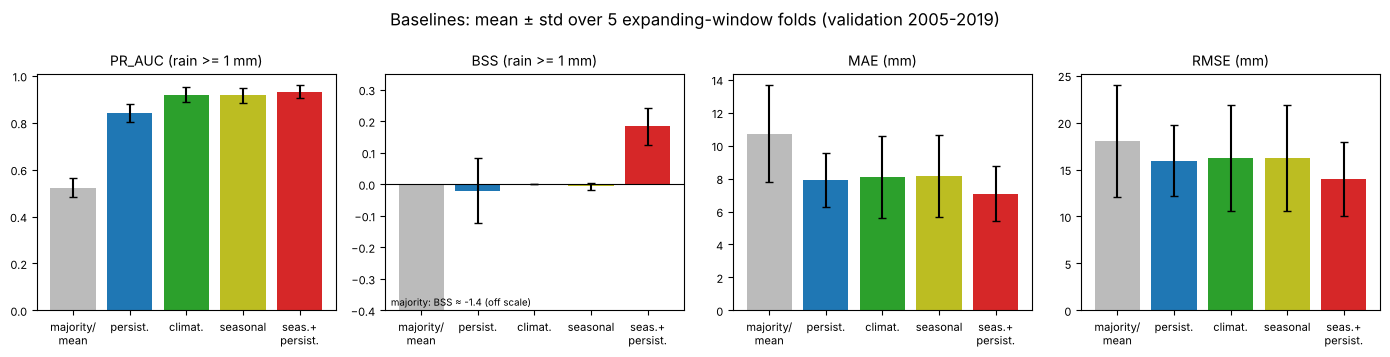

In [10]:
labels = {"majority": "majority/\nmean", "persistence": "persist.", "climatology": "climat.", "seasonal": "seasonal",
          "seasonal+persistence": "seas.+\npersist."}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (tgt, met) in zip(axes, [("y_cls", "PR_AUC"), ("y_cls", "BSS"), ("y_reg", "MAE"), ("y_reg", "RMSE")]):
    s = scores[(scores.target == tgt) & scores.split.isin(FOLDS)].groupby("model")[met].agg(["mean", "std"]).reindex(ORDER)
    ax.bar([labels[m] for m in ORDER], s["mean"], yerr=s["std"], capsize=3,
           color=["#bbbbbb", "tab:blue", "tab:green", "tab:olive", "tab:red"])
    ax.set_title(f"{met} ({'rain >= 1 mm' if tgt == 'y_cls' else 'mm'})", fontsize=10); ax.tick_params(labelsize=8)
    if met == "BSS": ax.axhline(0, color="k", lw=0.8); ax.set_ylim(-0.4, 0.35)
axes[1].text(0.02, 0.02, "majority: BSS ≈ -1.4 (off scale)", transform=axes[1].transAxes, fontsize=7)
fig.suptitle("Baselines: mean ± std over 5 expanding-window folds (validation 2005-2019)"); fig.tight_layout()
save(fig, "03_baseline_bars.png"); plt.show()

**Interpretation:** PR-AUC barely separates climatology, seasonal and the combined model (0.92–0.93) — the season dominates.
**BSS separates them clearly**: only the combined model has skill beyond climatology (0.18). For regression, the combined
model has the lowest MAE and RMSE, but the fold-to-fold error bars are large (RMSE std ≈ 4–6 mm) because fold 5 is so much
wetter; differences of < 1 mm MAE between baselines are within that spread.

**Decision:** for classification, BSS (with ROC-AUC/PR-AUC alongside) is the most informative headline metric.

**Paper note:** *Brier skill scores discriminated between reference forecasts more clearly than ranking-based scores, which
were dominated by the seasonal cycle.*

### Step 13 — How the 2016 regime jump affects the baselines (folds 4 and 5)

**WHAT:** per-fold values of the most diagnostic metrics: regression bias and MAE, MSESS of persistence, and BSS of
persistence and seasonal+persistence, next to the training/validation means.

**WHY:** fold 4 (2014–2016) straddles the jump and fold 5 (2017–2019) lies entirely after it, while their training data are
mostly pre-2016. Baselines that *learn a level* from training data (mean, climatology, seasonal) should become biased;
persistence, which copies the current level, should not.

**Look for:** bias in folds 4–5; whether persistence gains relative to climatology after the jump.

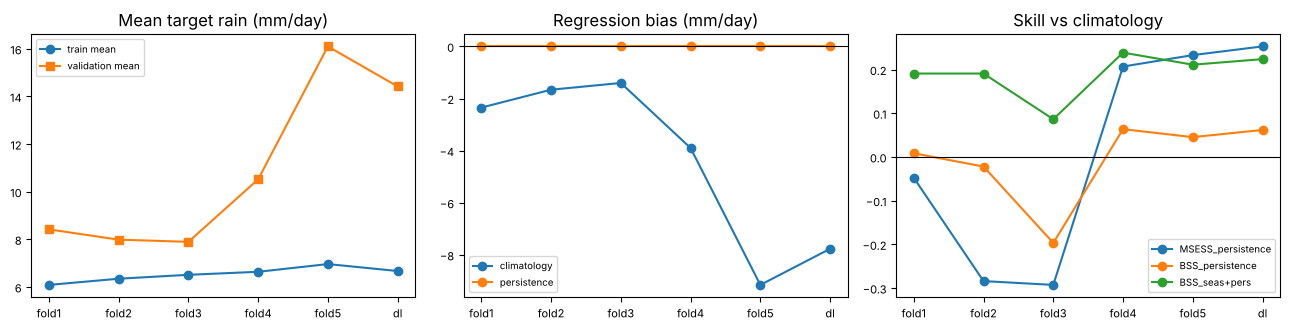

,mean_mm_train,mean_mm_val,bias_climatology,bias_persistence,MAE_climatology,MAE_persistence,MSESS_persistence,MSESS_seas+pers,BSS_persistence,BSS_seas+pers
dl,6.67,14.42,-7.77,0.0,10.97,9.66,0.25,0.34,0.06,0.22
fold1,6.09,8.42,-2.35,-0.0,7.46,7.33,-0.05,0.22,0.01,0.19
fold2,6.35,7.99,-1.66,-0.0,6.40,7.04,-0.28,0.12,-0.02,0.19
fold3,6.51,7.90,-1.40,-0.0,6.23,6.98,-0.29,0.12,-0.20,0.09
fold4,6.64,10.52,-3.90,-0.0,8.12,7.39,0.21,0.32,0.06,0.24
fold5,6.96,16.10,-9.15,-0.0,12.29,10.78,0.23,0.35,0.05,0.21


In [11]:
reg = scores[scores.target == "y_reg"].pivot(index="split", columns="model", values=["bias", "MAE", "MSESS"])
cls = scores[scores.target == "y_cls"].pivot(index="split", columns="model", values="BSS")
regime = pd.DataFrame({
    "mean_mm_train": split_tab["mean_mm_train"], "mean_mm_val": split_tab["mean_mm_val"],
    "bias_climatology": reg[("bias", "climatology")], "bias_persistence": reg[("bias", "persistence")],
    "MAE_climatology": reg[("MAE", "climatology")], "MAE_persistence": reg[("MAE", "persistence")],
    "MSESS_persistence": reg[("MSESS", "persistence")], "MSESS_seas+pers": reg[("MSESS", "seasonal+persistence")],
    "BSS_persistence": cls["persistence"], "BSS_seas+pers": cls["seasonal+persistence"]}).astype(float)
regime.round(3).to_csv(TAB / "03_baseline_regime_check.csv")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
x = FOLDS + ["dl"]
axes[0].plot(x, regime.loc[x, "mean_mm_train"], "o-", label="train mean"); axes[0].plot(x, regime.loc[x, "mean_mm_val"], "s-", label="validation mean")
axes[0].set_title("Mean target rain (mm/day)")
for m in ("climatology", "persistence"): axes[1].plot(x, regime.loc[x, f"bias_{m}"], "o-", label=m)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_title("Regression bias (mm/day)")
for c in ("MSESS_persistence", "BSS_persistence", "BSS_seas+pers"): axes[2].plot(x, regime.loc[x, c], "o-", label=c)
axes[2].axhline(0, color="k", lw=0.8); axes[2].set_title("Skill vs climatology")
for a in axes: a.legend(fontsize=7); a.tick_params(labelsize=8)
fig.tight_layout(); save(fig, "03_baseline_regime_check.png"); plt.show()
regime.round(2)

**Interpretation — the 2016 jump in the baselines:**
- Validation mean rain jumps to 10.5 (fold 4) and **16.1 mm/day (fold 5)** while training means stay ~6.6–7.0.
- Climatology bias: −1.4 to −2.4 mm/day in folds 1–3 → **−3.9 (fold 4) and −9.2 (fold 5)**; its MAE rises from ~6–8 to 12.3.
- Persistence stays unbiased, and its **MSESS flips sign**: −0.05 to −0.29 in folds 1–3 → **+0.21 / +0.23 in folds 4–5**.
  Persistence did not get better; its *reference* (climatology from old years) got worse. Skill scores are only as
  meaningful as their reference.
- Classification is affected less: BSS of the combined model is 0.09–0.24 across folds without a jump; fold 3 (2011–2013) is
  actually the weakest.

**Decision:** in Stage 4 report skill also **relative to seasonal + persistence** (not only climatology), and show fold 4–5
separately from folds 1–3 so that "skill" created by a broken reference is not mistaken for model quality. This confirms the
importance of the IMERG robustness analysis (Stage 6).

**Paper note:** *After 2016, reference forecasts that inherit the rainfall level of the training period became strongly
negatively biased (−9.2 mm day⁻¹ for climatology in 2017–2019), which artificially raised the MSE skill score of
persistence from negative values (2005–2013) to about 0.2 (2014–2019).*

### Step 14 — Skill within seasons (primary target)

**WHAT:** ROC-AUC computed separately for each season of the target day, averaged over the 5 folds.

**WHY:** your Stage-2 answer predicted that a high full-year ROC-AUC can hide weak skill inside a season. Climatology's
ROC-AUC comes almost entirely from separating winter from monsoon; within a season its ranking power should collapse.

**Alternatives considered:** BSS by season — also useful, but the climatology reference changes meaning within a season;
ROC-AUC is reference-free.

**Look for:** climatology's within-season ROC-AUC vs its full-year ~0.93, and which baseline keeps skill in the monsoon.

In [12]:
SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "pre-monsoon", 4: "pre-monsoon", 5: "pre-monsoon",
          6: "monsoon", 7: "monsoon", 8: "monsoon", 9: "monsoon", 10: "post-monsoon", 11: "post-monsoon"}
rows = []
for k in FOLDS:
    va = SPLITS[k][1]; season = td(va).month.map(SEASON); y = df.loc[va, "y_cls"].to_numpy()
    for name in ("climatology", "persistence", "seasonal+persistence"):
        p = PRED[k, "y_cls"][name]
        rows += [{"fold": k, "model": name, "season": s, "ROC_AUC": roc_auc_score(y[season == s], p[season == s])}
                 for s in ["pre-monsoon", "monsoon", "post-monsoon", "winter"]]
        rows.append({"fold": k, "model": name, "season": "all year", "ROC_AUC": roc_auc_score(y, p)})
season_auc = pd.DataFrame(rows).pivot_table(index="model", columns="season", values="ROC_AUC", aggfunc="mean")
season_auc = season_auc[["all year", "pre-monsoon", "monsoon", "post-monsoon", "winter"]]
season_auc.round(3).to_csv(TAB / "03_baseline_roc_auc_by_season.csv")
season_auc.round(3)

season,all year,pre-monsoon,monsoon,post-monsoon,winter
model,,,,,
climatology,0.928,0.820,0.703,0.840,0.653
persistence,0.878,0.803,0.632,0.829,0.680
seasonal+persistence,0.945,0.873,0.734,0.907,0.757


**Interpretation:** the full-year ROC-AUC is mostly "which season is it": climatology drops from 0.928 (all year) to
**0.70 in the monsoon** and 0.65 in winter (within a season it barely varies, so it can hardly rank days). Seasonal +
persistence keeps the most skill in every season (0.73 monsoon, 0.76 winter, 0.87–0.91 in the transition seasons);
persistence alone is weakest in the monsoon (0.63) because it rains almost every day anyway.

**Decision:** report within-season ROC-AUC for every model in Stage 4; **the monsoon (≈ 0.73 to beat) and the transition
seasons are where ML must prove itself.**

**Paper note:** *Within-season discrimination of the reference forecasts was substantially lower than their full-year
values (e.g. climatology ROC-AUC 0.70 in the monsoon versus 0.93 overall), indicating that annual-scale scores are dominated
by the seasonal cycle.*

### Step 15 — DL split (validation 2015–2019): scores, bootstrap CIs and reliability diagram

**WHAT:** (i) key scores on the DL split for Stage-5 reference; (ii) 95 % block-bootstrap confidence intervals (calendar
year-month blocks of the target date, 1,000 resamples) for selected scores; (iii) a reliability diagram.

**WHY:** CIs show which differences are larger than sampling noise (with ~60 monthly blocks, not ~1,800 independent days);
the reliability diagram shows whether "70 %" means 70 %.

**Alternatives considered:** daily (iid) bootstrap — CIs too narrow because days are autocorrelated.

**Look for:** whether the CI of BSS for seasonal+persistence excludes 0, and whether any baseline is badly calibrated in
2015–2019 (the new regime).

,ROC_AUC,PR_AUC,BSS,ECE,CSI,HSS,MAE,RMSE,bias,MSESS
model,,,,,,,,,,
majority,0.500,0.575,-1.548,0.092,0.000,0.000,14.192,25.238,-7.751,-0.193
persistence,0.898,0.884,0.062,0.056,0.840,0.796,9.663,19.967,0.000,0.253
climatology,0.944,0.957,0.000,0.099,0.812,0.769,10.974,23.102,-7.766,0.000
seasonal,0.943,0.949,-0.021,0.099,0.818,0.775,11.081,23.129,-7.732,-0.002
seasonal+persistence,0.959,0.963,0.224,0.059,0.839,0.797,9.019,18.725,-4.595,0.343


,estimate,CI 2.5%,CI 97.5%
BSS persistence,0.062,-0.041,0.146
BSS seasonal+persistence,0.224,0.173,0.274
ROC-AUC climatology,0.944,0.924,0.959
ROC-AUC seasonal+persistence,0.959,0.945,0.970
MAE persistence (mm),9.663,7.569,11.742
MAE seasonal+persistence (mm),9.019,7.053,10.897


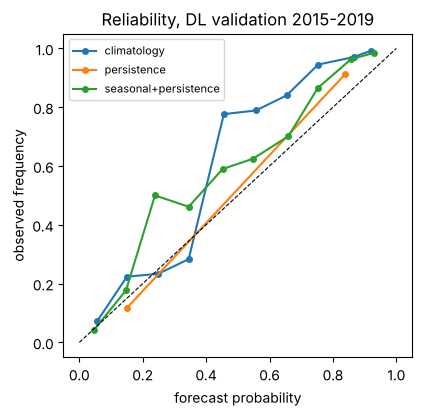

In [13]:
tr, va = SPLITS["dl"]
yc, yr, P, R = df.loc[va, "y_cls"].to_numpy(), df.loc[va, "y_reg"].to_numpy(), PRED["dl", "y_cls"], PRED["dl", "y_reg"]
dl_tab = scores[scores.split == "dl"].set_index(["target", "model"])
display(pd.concat([dl_tab.loc["y_cls", ["ROC_AUC", "PR_AUC", "BSS", "ECE", "CSI", "HSS"]],
                   dl_tab.loc["y_reg", ["MAE", "RMSE", "bias", "MSESS"]]], axis=1).reindex(ORDER).round(3))

bss = lambda y, p, r: 1 - np.mean((p - y) ** 2) / np.mean((r - y) ** 2)
mae = lambda y, f: np.mean(np.abs(f - y))
dates = td(va)
ci = {"BSS persistence": M.block_bootstrap(bss, dates, yc, P["persistence"], P["climatology"]),
      "BSS seasonal+persistence": M.block_bootstrap(bss, dates, yc, P["seasonal+persistence"], P["climatology"]),
      "ROC-AUC climatology": M.block_bootstrap(roc_auc_score, dates, yc, P["climatology"]),
      "ROC-AUC seasonal+persistence": M.block_bootstrap(roc_auc_score, dates, yc, P["seasonal+persistence"]),
      "MAE persistence (mm)": M.block_bootstrap(mae, dates, yr, R["persistence"]),
      "MAE seasonal+persistence (mm)": M.block_bootstrap(mae, dates, yr, R["seasonal+persistence"])}
ci = pd.DataFrame(ci, index=["estimate", "CI 2.5%", "CI 97.5%"]).T
ci.round(3).to_csv(TAB / "03_baseline_dl_bootstrap_ci.csv")
display(ci.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4.2))
for name in ("climatology", "persistence", "seasonal+persistence"):
    c = M.calibration(yc, P[name]); ax.plot(c["mean_predicted"], c["observed_frequency"], "o-", ms=4, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set(xlabel="forecast probability", ylabel="observed frequency",
                                               title="Reliability, DL validation 2015-2019"); ax.legend(fontsize=8)
save(fig, "03_baseline_reliability_dl.png"); plt.show()

**Interpretation (DL split, validation 2015–2019):**
- Seasonal + persistence: BSS **0.224, 95 % CI [0.173, 0.274]** — skill over climatology is clearly above zero.
  Persistence: BSS 0.062, CI [−0.041, 0.146] — not distinguishable from climatology.
- ROC-AUC: 0.959 [0.945, 0.970] vs climatology 0.944 [0.924, 0.959]: the intervals overlap.
- MAE: persistence 9.66 [7.57, 11.74] vs combined 9.02 [7.05, 10.90] mm — **wide, overlapping intervals**: with only ~60
  monthly blocks, regression differences of < 1–2 mm/day cannot be called significant.
- Reliability: climatology lies **above the diagonal** (observed frequency > forecast), i.e. it under-forecasts rain in the
  new regime (ECE 0.099); persistence and the combined model are better calibrated (ECE ≈ 0.06).

**Decision:** keep these values as the Stage-5 reference (`03_baseline_scores_dl_split.csv`, `03_baseline_dl_bootstrap_ci.csv`).
In Stage 4/5, model comparisons should use **paired** bootstrap differences (same resampled months for both models), which
are much tighter than comparing two separate CIs.

**Paper note:** *Block-bootstrap confidence intervals (monthly blocks) showed that the Brier skill of the seasonal-persistence
reference was robustly positive (0.22, 95 % CI 0.17–0.27), whereas differences in mean absolute error between reference
forecasts were within sampling uncertainty.*

## Implications: how much skill is available from season and persistence, and what Stage 4 must beat

1. **Season explains most of the "easy" skill.** Climatology alone: ROC-AUC 0.93, PR-AUC 0.92, CSI 0.77. Any model
   evaluated on full-year ROC-AUC will look excellent; this tells us nothing about weather skill.
2. **Persistence adds complementary skill.** Season + rain-today: BSS 0.18 ± 0.06, CSI 0.81, MSESS 0.23 ± 0.11.
3. **Bars for Stage 4 (5-fold mean ± std, ≥ 1 mm):**

| task | metric | bar = seasonal + persistence | best single baseline |
|---|---|---|---|
| classification | **BSS vs climatology** | **0.184 ± 0.058** | 0.000 (climatology) |
| | ROC-AUC / PR-AUC | 0.945 / 0.932 | 0.928 / 0.920 (climatology) |
| | CSI / HSS | 0.813 / 0.780 | 0.791 / 0.757 (persistence) |
| | log loss | 0.298 | 0.353 (climatology) |
| | monsoon ROC-AUC | 0.734 | 0.703 (climatology) |
| regression | **MAE (mm)** | **7.08 ± 1.68** | 7.90 (persistence) |
| | RMSE (mm) / MSESS | 14.0 / 0.228 | 15.96 (persistence) / 0.000 |
| | recall ≥ 50 mm | 0.06 | 0.30 (persistence) |

4. **Proposals for your approval (logged as pending in DECISIONS.md):**
   - **(P1) Pre-register primary metrics before Stage 4:** classification — BSS vs climatology (headline) plus ROC-AUC,
     PR-AUC and CSI at a frozen threshold; regression — MAE and MSESS (plus wet-day MAE). Everything else is secondary.
     This prevents choosing the metric that makes a model look best afterwards.
   - **(P2) Refine the rule-11 trigger.** A 6-parameter logistic model already reaches ROC-AUC 0.965 in fold 5, so
     "ROC-AUC > 0.95 ⇒ bug" would fire on a baseline. Proposed triggers: BSS > 0.45, within-monsoon ROC-AUC > 0.90, or
     MSESS > 0.6 — i.e. far beyond the seasonal + persistence bar.
   - **(P3) Report Stage-4 skill also relative to seasonal + persistence**, and folds 1–3 vs 4–5 separately.

## SKEPTICAL-REVIEWER: how a critical reviewer would attack this stage

| # | Criticism | Our answer / status |
|---|---|---|
| 1 | *"Your skill scores use a climatology that is wrong after 2016."* | **Valid.** Step 13: persistence MSESS jumps from −0.29 to +0.23 purely because the reference degrades. Mitigation: also report skill vs seasonal + persistence (P3), per-fold results, IMERG robustness (Stage 6). |
| 2 | *"Every validation period is wetter than training — your evaluation measures adaptation to a data artefact."* | **Valid, and not only after 2016** (Step 2: folds 1–3 are also wetter, from the ~2000 break). Mitigation: training-window ablation (start 2000 / 2016) and IMERG target in Stage 6. |
| 3 | *"Persistence in a reanalysis is artificially strong."* | **Plausible.** MERRA-2 rain is spatially smooth with long drizzle spells (wet spells up to 138 days). Station-based studies may see weaker persistence; we must not compare our absolute scores with gauge studies without saying this. IMERG check in Stage 6. |
| 4 | *"5 folds with overlapping training sets are not independent; the std understates uncertainty."* | **Valid.** The fold std describes variation across periods, not a confidence interval. We add block-bootstrap CIs; for model comparisons we will use paired bootstrap differences. |
| 5 | *"You chose the decision threshold on training data."* | For baselines (≤ 6 parameters) in-sample probabilities are essentially unbiased. **For ML models they are not** (over-fitted training probabilities) → in Stage 4 the threshold must come from out-of-fold predictions on an inner chronological split, never from the fold's validation block. |
| 6 | *"This is not a real forecast."* | **Correct.** Inputs are reanalysis values for day t, released weeks later; the study is a *hindcast* (perfect-prognosis) experiment. Scores are an upper bound for an operational system. Must be stated in the paper. |
| 7 | *"High ROC-AUC everywhere — is something leaking?"* | No: Stage 2 leakage tests passed, and Step 14 shows the full-year ROC-AUC comes from the season (climatology 0.93 overall, 0.70 within the monsoon). Hence P2. |
| 8 | *"Too many metrics — you can pick the favourable one."* | Risk acknowledged → pre-registration of primary metrics (P1) before any ML model is trained. |
| 9 | *"Small details: 29 Feb, seasonal features of day t vs target day t+1."* | Climatology pools 366 days with a ±7-day circular window (29 Feb borrows from neighbours); the 1-day offset of the sin/cos features is negligible (< 0.3 % of the annual cycle). |
| 10 | *"Regression RMSE is dominated by a few extreme days in 2017–2019."* | Yes (Stage 1: 13 of the 20 largest days are in 2017/2019). We report MAE as primary, wet-day MAE, and heavy-rain recall/precision separately. |

## Stage 3 summary

| Item | Result |
|---|---|
| Splits | 5 expanding folds (validation 2005–2019, 3 years each) + DL split (2015–2019); split by target date; 1-day purge; test locked behind `confirm_final=True`; 23 tests pass |
| Random k-fold | would expose ~80 % of validation targets as training inputs → excluded |
| Metrics | all requested metrics + threshold selection + monthly block bootstrap; 9 hand-checked tests pass |
| Best reference | **seasonal + persistence**: BSS 0.18 ± 0.06, ROC-AUC 0.945, CSI 0.81; MAE 7.08 mm, MSESS 0.23 |
| Season vs persistence | season: ROC-AUC 0.93 but only 0.70 within the monsoon; persistence: CSI 0.79, unbiased under the regime shift |
| 2016 effect | climatology bias −9.2 mm/day in fold 5; persistence MSESS turns positive only because the reference fails |
| Pending your approval | P1 primary metrics, P2 rule-11 triggers, P3 skill vs seasonal + persistence |

Outputs: `src/splits.py`, `src/metrics.py`, `src/baselines.py`, `tests/test_splits.py`, `tests/test_metrics.py`,
`reports/tables/03_*.csv`, `reports/figures/03_*.png`.